## Evaluation of the Standard Filters

In [ ]:
# import os
# import joblib

# # ==========================================
# # 1. PATH CONFIGURATION (STATIC THRESHOLDS)
# # ==========================================
# # Define the paths for both targeted cohorts
# results_paths = {
#     "Post-Operative Cohort": 'tuning_results/completed_static_post_op.pkl',
#     "Diabetes-Related Cohort": 'tuning_results/completed_static_diabetes.pkl'
# }

# # ==========================================
# # 2. ITERATE, LOAD, AND PRINT RESULTS
# # ==========================================
# # Dictionary to store the final parameters for both cohorts
# all_optimized_thresholds = {}

# for cohort_name, path in results_paths.items():
#     print("\n" + "*"*55)
#     print(f" PROCESSING: {cohort_name}")
#     print("*"*55)

#     if os.path.exists(path):
#         # Load the dictionary generated by the Optuna terminal script
#         completed_studies = joblib.load(path)
#         print(f" Successfully loaded STATIC optimization results from: {path}")
        
#         # ------------------------------------------
#         # 3. EXTRACT OPTIMAL THRESHOLDS (COMBINED ONLY)
#         # ------------------------------------------
#         # Combined Optimal Parameters
#         best_comb_raw_drift_ph = completed_studies['combined']['raw'].best_params['raw_drift_ph']
#         best_comb_raw_drift_temp = completed_studies['combined']['raw'].best_params['raw_drift_temp']
#         best_comb_raw_decay = completed_studies['combined']['raw'].best_params['raw_leakage']
        
#         best_comb_agg_pers = completed_studies['combined']['agg'].best_params['agg_persistence']
#         best_comb_agg_drift_ph = completed_studies['combined']['agg'].best_params['agg_abs_drift_ph']
#         best_comb_agg_drift_temp = completed_studies['combined']['agg'].best_params['agg_abs_drift_temp']

#         # ------------------------------------------
#         # 4. PRINT SUMMARY TABLE
#         # ------------------------------------------
#         print("\n" + "="*45)
#         print(f" FINAL OPTIMIZED STATIC THRESHOLDS & DECAY")
#         print("="*45)
#         print(f"Combined Raw Drift (pH):  {best_comb_raw_drift_ph:.4f}")
#         print(f"Combined Raw Drift (T):   {best_comb_raw_drift_temp:.4f}")
#         print(f"Combined Raw Decay (d):   {best_comb_raw_decay:.4f}") 
#         print("-" * 45)
#         print(f"Combined Agg Persistence: {best_comb_agg_pers}")
#         print(f"Combined Agg Drift (pH):  {best_comb_agg_drift_ph:.4f}")
#         print(f"Combined Agg Drift (T):   {best_comb_agg_drift_temp:.4f}")
#         print("="*45 + "\n")

#         # ------------------------------------------
#         # 5. STORE IN DICTIONARY
#         # ------------------------------------------
#         all_optimized_thresholds[cohort_name] = {
#             'comb_raw_drift_ph': best_comb_raw_drift_ph, 
#             'comb_raw_drift_temp': best_comb_raw_drift_temp,
#             'comb_raw_leakage': best_comb_raw_decay, 
#             'comb_agg_pers': best_comb_agg_pers,
#             'comb_agg_drift_ph': best_comb_agg_drift_ph, 
#             'comb_agg_drift_temp': best_comb_agg_drift_temp
#         }

#     else:
#         print(f" ERROR: Results file not found at {path}")

# # Print the final compiled dictionary for both cohorts
# print("\nFinal Dictionary of All Extracted Thresholds:")
# print(all_optimized_thresholds)


*******************************************************
 PROCESSING: Post-Operative Cohort
*******************************************************
 Successfully loaded STATIC optimization results from: tuning_results/completed_static_post_op.pkl

 FINAL OPTIMIZED STATIC THRESHOLDS & DECAY
Combined Raw Drift (pH):  0.5600
Combined Raw Drift (T):   4.6000
Combined Raw Decay (d):   0.9074
---------------------------------------------
Combined Agg Persistence: 1
Combined Agg Drift (pH):  0.1500
Combined Agg Drift (T):   0.3000


*******************************************************
 PROCESSING: Diabetes-Related Cohort
*******************************************************
 Successfully loaded STATIC optimization results from: tuning_results/completed_static_diabetes.pkl

 FINAL OPTIMIZED STATIC THRESHOLDS & DECAY
Combined Raw Drift (pH):  0.4600
Combined Raw Drift (T):   5.0000
Combined Raw Decay (d):   0.8713
---------------------------------------------
Combined Agg Persistence: 1
Co

In [ ]:
# import os
# import joblib
# import pandas as pd
# import numpy as np
# from diseases import DiseaseSimulator
# from drift_detection import AnomalyDetector

# def run_head_to_head_comparison():
#     # 1. Path to optimized study parameters
#     results_path = 'tuning_results/completed_studies_BEST.pkl'
#     if not os.path.exists(results_path):
#         print(f"[ERROR] Optimization file missing at: '{results_path}'")
#         print("Please verify your path or run your optimization sweep first.")
#         return

#     print(f"[INFO] Extracting optimized hyperparameters from '{results_path}'...")
#     st = joblib.load(results_path)
    
#     # Map the best optimized parameters exactly like your ComprehensiveTestSuite
#     params = {
#         'ph_raw_drift': st['ph']['raw'].best_params['raw_drift_threshold'],
#         'ph_raw_leakage': st['ph']['raw'].best_params['raw_leakage'],
#         'ph_agg_pers': st['ph']['agg'].best_params['agg_persistence'],
#         'ph_agg_drift': st['ph']['agg'].best_params['agg_abs_drift'],
#         'temp_raw_drift': st['temp']['raw'].best_params['raw_drift_threshold'],
#         'temp_raw_leakage': st['temp']['raw'].best_params['raw_leakage'],
#         'temp_agg_pers': st['temp']['agg'].best_params['agg_persistence'],
#         'temp_agg_drift': st['temp']['agg'].best_params['agg_abs_drift'],
#         'comb_raw_drift_ph': st['combined']['raw'].best_params['raw_drift_ph'],
#         'comb_raw_drift_temp': st['combined']['raw'].best_params['raw_drift_temp'],
#         'comb_raw_leakage': st['combined']['raw'].best_params['raw_leakage'],
#         'comb_agg_pers': st['combined']['agg'].best_params['agg_persistence'],
#         'comb_agg_drift_ph': st['combined']['agg'].best_params['agg_abs_drift_ph'],
#         'comb_agg_drift_temp': st['combined']['agg'].best_params['agg_abs_drift_temp']
#     }

#     # 2. Initialize simulator
#     simulator = DiseaseSimulator()
#     disease_dict = simulator.diseases
#     alpha, beta = 0.3, 0.10

#     # Scenarios to test
#     test_scenarios = [
#         {"key": "endocarditis_temp", "is_healthy": False, "name": "Endocarditis (Temperature)"},
#         {"key": "systemic_fever_temp", "is_healthy": True, "name": "Healthy Control Baseline"}
#     ]

#     for scenario in test_scenarios:
#         d_key = scenario["key"]
#         is_healthy = scenario["is_healthy"]
        
#         print("\n" + "="*80)
#         print(f"  MODELED PATIENT SCENARIO: {scenario['name'].upper()}")
#         print("="*80)

#         # 3. Simulate patient track and dynamically construct the optimized filter
#         if is_healthy:
#             raw_df, agg_df, t_start = simulator.run_single_disease(alpha, beta, 'systemic_fever_temp', safe_start_time=86400)
            
#             # Replicates _worker_healthy parameter mapping block dynamically
#             detector = AnomalyDetector(
#                 alpha=alpha, beta=beta, use_z_score=False,
#                 raw_drift_threshold=params['temp_raw_drift'],
#                 raw_leakage=params['temp_raw_leakage'],
#                 agg_persistence=params['temp_agg_pers'],
#                 agg_abs_drift=params['temp_agg_drift']
#             )
#             _, raw_alerts = detector.detect_raw_stream(raw_df)
#             _, agg_alerts = detector.detect_aggregated_stream(agg_df)
#         else:
#             d_info = disease_dict[d_key]
#             if d_info['type'] == 'single':
#                 raw_df, agg_df, t_start = simulator.run_single_disease(alpha, beta, d_key)
#                 p_prefix = d_info['param'] # 'ph' or 'temp'
                
#                 detector = AnomalyDetector(
#                     alpha=alpha, beta=beta, use_z_score=False,
#                     raw_drift_threshold=params[f'{p_prefix}_raw_drift'],
#                     raw_leakage=params[f'{p_prefix}_raw_leakage'],
#                     agg_persistence=params[f'{p_prefix}_agg_pers'],
#                     agg_abs_drift=params[f'{p_prefix}_agg_drift']
#                 )
#                 _, raw_alerts = detector.detect_raw_stream(raw_df)
#                 _, agg_alerts = detector.detect_aggregated_stream(agg_df)
#             else:
#                 raw_df, agg_df, t_start = simulator.run_combined_disease(alpha, beta, d_key)
                
#                 detector = AnomalyDetector(
#                     alpha=alpha, beta=beta, beta_ph=0.10, beta_temp=0.01, use_z_score=False,
#                     raw_drift_ph=params['comb_raw_drift_ph'],
#                     raw_drift_temp=params['comb_raw_drift_temp'],
#                     raw_leakage=params['comb_raw_leakage'],
#                     agg_persistence=params['comb_agg_pers'],
#                     agg_abs_drift_ph=params['comb_agg_drift_ph'],
#                     agg_abs_drift_temp=params['comb_agg_drift_temp']
#                 )
#                 _, raw_alerts = detector.detect_combined_raw_stream(raw_df)
#                 _, agg_alerts = detector.detect_combined_aggregated_stream(agg_df)

#         # ----------------------------------------------------
#         # EXECUTION STREAM 1: RAW ASYNCHRONOUS STREAM FILTER
#         # ----------------------------------------------------
#         print("\n  [1] RAW STREAM FILTER EVALUATION")
#         print("  " + "-"*40)
#         if not raw_alerts:
#             print("    No alarms triggered in the raw asynchronous stream.")
#         else:
#             for zone_id, det_val in sorted(raw_alerts.items()):
#                 t_det = min([t for t in det_val.values() if t is not None]) if isinstance(det_val, dict) else det_val
#                 print(f"    --> Zone {zone_id:2d} alarm triggered at time {t_det/3600:5.2f} hours")
        
#         # Calculate Raw Top-5 Ranking
#         triggered_raw = set(raw_alerts.keys())
#         print("\n    -> Raw Stream Top-5 Classification Match:")
#         if is_healthy and len(triggered_raw) == 0:
#             print("       1. HEALTHY BASELINE (100% Certainty)")
#         elif len(triggered_raw) == 0:
#             print("       [Undetected / False Negative]")
#         else:
#             raw_jaccard = {}
#             for comp_key, comp_info in disease_dict.items():
#                 if comp_key == 'healthy': continue
#                 dz_set = set(comp_info['zones'])
#                 intersection = len(triggered_raw.intersection(dz_set))
#                 union = len(triggered_raw.union(dz_set))
#                 raw_jaccard[comp_key] = intersection / union if union > 0 else 0.0
            
#             ranked_raw = sorted(raw_jaccard.keys(), key=lambda k: raw_jaccard[k], reverse=True)
#             for idx, r_key in enumerate(ranked_raw[:5]):
#                 print(f"       {idx+1}. {r_key.upper()} (Jaccard Score: {raw_jaccard[r_key]:.2f})")

#         # ----------------------------------------------------
#         # EXECUTION STREAM 2: ADAPTIVE AGGREGATED STREAM FILTER
#         # ----------------------------------------------------
#         print("\n  [2] ADAPTIVE AGGREGATED STREAM FILTER EVALUATION")
#         print("  " + "-"*40)
#         if not agg_alerts:
#             print("    No alarms triggered (Aggregated Binomial Confidence Gating Successful).")
#         else:
#             for zone_id, det_val in sorted(agg_alerts.items()):
#                 t_det = min([t for t in det_val.values() if t is not None]) if isinstance(det_val, dict) else det_val
#                 print(f"    --> Zone {zone_id:2d} alarm triggered at time {t_det/3600:5.2f} hours")
        
#         # Calculate Aggregated Top-5 Ranking
#         triggered_agg = set(agg_alerts.keys())
#         print("\n    -> Aggregated Stream Top-5 Classification Match:")
#         if is_healthy and len(triggered_agg) == 0:
#             print("       1. HEALTHY BASELINE (100% Certainty - Noise Successfully Suppressed)")
#         elif len(triggered_agg) == 0:
#             print("       [Undetected / False Negative]")
#         else:
#             agg_jaccard = {}
#             for comp_key, comp_info in disease_dict.items():
#                 if comp_key == 'healthy': continue
#                 dz_set = set(comp_info['zones'])
#                 intersection = len(triggered_agg.intersection(dz_set))
#                 union = len(triggered_agg.union(dz_set))
#                 agg_jaccard[comp_key] = intersection / union if union > 0 else 0.0
            
#             ranked_agg = sorted(agg_jaccard.keys(), key=lambda k: agg_jaccard[k], reverse=True)
#             for idx, r_key in enumerate(ranked_agg[:5]):
#                 print(f"       {idx+1}. {r_key.upper()} (Jaccard Score: {agg_jaccard[r_key]:.2f})")

# # Run head-to-head tracking setup with optimal parameter injections
# run_head_to_head_comparison()

[INFO] Extracting optimized hyperparameters from 'tuning_results/completed_studies_BEST.pkl'...

  MODELED PATIENT SCENARIO: ENDOCARDITIS (TEMPERATURE)
[ENDOCARDITIS_TEMP] Velocity: 12.0h | Random Onset: Hour 8.3 | Peak: Hour 20.3

  [1] RAW STREAM FILTER EVALUATION
  ----------------------------------------
    --> Zone  1 alarm triggered at time 15.54 hours
    --> Zone  2 alarm triggered at time 18.49 hours
    --> Zone  3 alarm triggered at time 14.66 hours
    --> Zone 20 alarm triggered at time  1.63 hours

    -> Raw Stream Top-5 Classification Match:
       1. ENDOCARDITIS_TEMP (Jaccard Score: 0.75)
       2. DKA_PH (Jaccard Score: 0.50)
       3. MALIGNANT_HYPERTHERMIA_COMBINED (Jaccard Score: 0.50)
       4. SYSTEMIC_ALKALOSIS_PH (Jaccard Score: 0.20)
       5. SYSTEMIC_FEVER_TEMP (Jaccard Score: 0.20)

  [2] ADAPTIVE AGGREGATED STREAM FILTER EVALUATION
  ----------------------------------------
    --> Zone  1 alarm triggered at time 13.35 hours
    --> Zone  2 alarm trigger

In [ ]:
# import os
# import joblib
# import pandas as pd
# import numpy as np
# from diseases import DiseaseSimulator
# from drift_detection import AnomalyDetector

# def run_targeted_cohort_comparison():
#     # 1. Target the post-op cohort optimization study file
#     cohort_name = 'post_op'
#     results_path = f'tuning_results/completed_static_{cohort_name}.pkl'
    
#     if not os.path.exists(results_path):
#         print(f"[ERROR] Cohort optimization file missing at: '{results_path}'")
#         print(f"Please verify your path or run the targeted static optimization sweep for '{cohort_name}' first.")
#         return

#     print(f"[INFO] Extracting optimized combined hyperparameters from '{results_path}'...")
#     st = joblib.load(results_path)
    
#     # Map the best optimized params exactly like your TargetedCohortTestSuite
#     params = {
#         'comb_raw_drift_ph': st['combined']['raw'].best_params['raw_drift_ph'],
#         'comb_raw_drift_temp': st['combined']['raw'].best_params['raw_drift_temp'],
#         'comb_raw_leakage': st['combined']['raw'].best_params['raw_leakage'],
#         'comb_agg_pers': st['combined']['agg'].best_params['agg_persistence'],
#         'comb_agg_drift_ph': st['combined']['agg'].best_params['agg_abs_drift_ph'],
#         'comb_agg_drift_temp': st['combined']['agg'].best_params['agg_abs_drift_temp']
#     }
    
#     # 2. Initialize core simulator and map global disease dictionary
#     simulator = DiseaseSimulator()
#     disease_dict = simulator.diseases
#     alpha, beta = 0.3, 0.10
    
#     # Initialize AnomalyDetector using the dynamically loaded COMBINED parameters
#     detector = AnomalyDetector(
#         alpha=alpha, beta=beta, beta_ph=0.10, beta_temp=0.01, target_confidence=70.0,
#         use_z_score=False,
#         raw_drift_ph=params['comb_raw_drift_ph'],
#         raw_drift_temp=params['comb_raw_drift_temp'],
#         raw_leakage=params['comb_raw_leakage'],
#         agg_persistence=params['comb_agg_pers'],
#         agg_abs_drift_ph=params['comb_agg_drift_ph'],
#         agg_abs_drift_temp=params['comb_agg_drift_temp']
#     )

#     # Targeted Cohort Scenarios
#     test_scenarios = [
#         {"key": "dvt_temp", "is_healthy": False, "name": "DVT (Temperature) - Post-Op Cohort Case"},
#         {"key": "healthy_control", "is_healthy": True, "name": "Matched Healthy Control (Post-Op Cohort Control)"}
#     ]

#     for scenario in test_scenarios:
#         d_key = scenario["key"]
#         is_healthy = scenario["is_healthy"]
        
#         print("\n" + "="*80)
#         print(f"  TARGETED COHORT PATIENT SCENARIO: {scenario['name'].upper()}")
#         print("="*80)

#         # 3. Force BOTH tracks through the Combined multi-sensor pipeline 
#         if is_healthy:
#             # Replicates your targeted cohort healthy worker track exactly
#             raw_df, agg_df, t_start = simulator.run_combined_disease(alpha, beta, 'systemic_fever_temp', safe_start_time=86400)
#         else:
#             raw_df, agg_df, t_start = simulator.run_combined_disease(alpha, beta, d_key)

#         # Force execution through the Combined Dual-Sensor alert streams
#         _, raw_alerts = detector.detect_combined_raw_stream(raw_df)
#         _, agg_alerts = detector.detect_combined_aggregated_stream(agg_df)

#         # ----------------------------------------------------
#         # EXECUTION STREAM 1: RAW ASYNCHRONOUS STREAM FILTER
#         # ----------------------------------------------------
#         print("\n  [1] TARGETED COHORT: RAW COMBINED ALERT STREAM")
#         print("  " + "-"*48)
#         if not raw_alerts:
#             print("    No alarms triggered in the raw asynchronous combined stream.")
#         else:
#             for zone_id, det_val in sorted(raw_alerts.items()):
#                 t_det = min([t for t in det_val.values() if t is not None]) if isinstance(det_val, dict) else det_val
#                 print(f"    --> Zone {zone_id:2d} alarm triggered at time {t_det/3600:5.2f} hours")
        
#         # Calculate Raw Top-5 Ranking against the 15 global possibilities
#         triggered_raw = set(raw_alerts.keys())
#         print("\n    -> Raw Stream Top-5 Classification Diagnosis:")
#         if is_healthy and len(triggered_raw) == 0:
#             print("       1. HEALTHY BASELINE (100% Certainty)")
#         elif len(triggered_raw) == 0:
#             print("       [Undetected / False Negative]")
#         else:
#             raw_jaccard = {}
#             for comp_key, comp_info in disease_dict.items():
#                 if comp_key == 'healthy': continue
#                 dz_set = set(comp_info['zones'])
#                 intersection = len(triggered_raw.intersection(dz_set))
#                 union = len(triggered_raw.union(dz_set))
#                 raw_jaccard[comp_key] = intersection / union if union > 0 else 0.0
            
#             ranked_raw = sorted(raw_jaccard.keys(), key=lambda k: raw_jaccard[k], reverse=True)
#             for idx, r_key in enumerate(ranked_raw[:5]):
#                 print(f"       {idx+1}. {r_key.upper()} (Jaccard Score: {raw_jaccard[r_key]:.2f})")

#         # ----------------------------------------------------
#         # EXECUTION STREAM 2: ADAPTIVE AGGREGATED STREAM FILTER
#         # ----------------------------------------------------
#         print("\n  [2] TARGETED COHORT: ADAPTIVE AGGREGATED COMBINED ALERT STREAM")
#         print("  " + "-"*48)
#         if not agg_alerts:
#             print("    No alarms triggered (Binomial Confidence Gating Secured Absolute Silence).")
#         else:
#             for zone_id, det_val in sorted(agg_alerts.items()):
#                 t_det = min([t for t in det_val.values() if t is not None]) if isinstance(det_val, dict) else det_val
#                 print(f"    --> Zone {zone_id:2d} alarm triggered at time {t_det/3600:5.2f} hours")
        
#         # Calculate Aggregated Top-5 Ranking against the 15 global possibilities
#         triggered_agg = set(agg_alerts.keys())
#         print("\n    -> Aggregated Stream Top-5 Classification Diagnosis:")
#         if is_healthy and len(triggered_agg) == 0:
#             print("       1. HEALTHY BASELINE (100% Certainty - Noise Successfully Suppressed)")
#         elif len(triggered_agg) == 0:
#             print("       [Undetected / False Negative]")
#         else:
#             agg_jaccard = {}
#             for comp_key, comp_info in disease_dict.items():
#                 if comp_key == 'healthy': continue
#                 dz_set = set(comp_info['zones'])
#                 intersection = len(triggered_agg.intersection(dz_set))
#                 union = len(triggered_agg.union(dz_set))
#                 agg_jaccard[comp_key] = intersection / union if union > 0 else 0.0
            
#             ranked_agg = sorted(agg_jaccard.keys(), key=lambda k: agg_jaccard[k], reverse=True)
#             for idx, r_key in enumerate(ranked_agg[:5]):
#                 print(f"       {idx+1}. {r_key.upper()} (Jaccard Score: {agg_jaccard[r_key]:.2f})")

# # Run the strict cohort evaluation setup
# run_targeted_cohort_comparison()

[INFO] Extracting optimized combined hyperparameters from 'tuning_results/completed_static_post_op.pkl'...

  TARGETED COHORT PATIENT SCENARIO: DVT (TEMPERATURE) - POST-OP COHORT CASE


[DVT_TEMP] Velocity: 8.0h | Random Onset: Hour 8.6 | Peak: Hour 16.6

  [1] TARGETED COHORT: RAW COMBINED ALERT STREAM
  ------------------------------------------------
    --> Zone 19 alarm triggered at time 11.95 hours

    -> Raw Stream Top-5 Classification Diagnosis:
       1. ARTERIAL_OCCLUSION_TEMP (Jaccard Score: 1.00)
       2. DVT_TEMP (Jaccard Score: 1.00)
       3. ISCHEMIA_COMBINED (Jaccard Score: 1.00)
       4. SYSTEMIC_ALKALOSIS_PH (Jaccard Score: 0.05)
       5. SYSTEMIC_FEVER_TEMP (Jaccard Score: 0.05)

  [2] TARGETED COHORT: ADAPTIVE AGGREGATED COMBINED ALERT STREAM
  ------------------------------------------------
    --> Zone 14 alarm triggered at time  1.61 hours
    --> Zone 19 alarm triggered at time 12.15 hours

    -> Aggregated Stream Top-5 Classification Diagnosis:
       1. ARTERIAL_OCCLUSION_TEMP (Jaccard Score: 0.50)
       2. DVT_TEMP (Jaccard Score: 0.50)
       3. ISCHEMIA_COMBINED (Jaccard Score: 0.50)
       4. SYSTEMIC_ALKALOSIS_PH (Jaccard Score: 

# 5.1

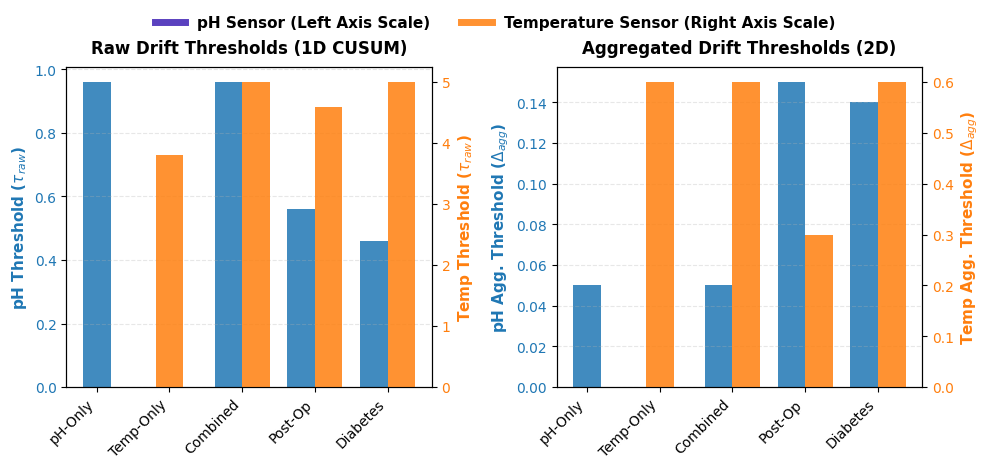

In [5]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D

# Data extracted from optimization results
scenarios = ['pH-Only', 'Temp-Only', 'Combined', 'Post-Op', 'Diabetes']
x = np.arange(len(scenarios))

# Raw Stream (1D CUSUM) Drift Thresholds
tau_ph = [0.9600, np.nan, 0.9600, 0.5600, 0.4600]
tau_temp = [np.nan, 3.8000, 5.0000, 4.6000, 5.0000]

# Aggregated Stream (Adaptive 2D) Drift Thresholds
delta_ph = [0.0500, np.nan, 0.0500, 0.1500, 0.1400]
delta_temp = [np.nan, 0.6000, 0.6000, 0.3000, 0.6000]

# Setup figure with 2 panels - well-embedded layout
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
fig.patch.set_facecolor('white')

# Panel Layout Mapping
ax1, ax1_twin = axes[0], axes[0].twinx()
ax2, ax2_twin = axes[1], axes[1].twinx()

# Standardize the exact width for ALL bars
uniform_width = 0.38 

# Loop through scenarios to position bars uniformly
for i in range(len(scenarios)):
    has_ph = not np.isnan(tau_ph[i])
    has_temp = not np.isnan(tau_temp[i])
    
    if has_ph and has_temp:
        # Dual-sensor tracking scenarios
        ax1.bar(i - uniform_width/2, tau_ph[i], uniform_width, color='#1f77b4', alpha=0.85)
        ax1_twin.bar(i + uniform_width/2, tau_temp[i], uniform_width, color='#ff7f0e', alpha=0.85)
        
        ax2.bar(i - uniform_width/2, delta_ph[i], uniform_width, color='#1f77b4', alpha=0.85)
        ax2_twin.bar(i + uniform_width/2, delta_temp[i], uniform_width, color='#ff7f0e', alpha=0.85)
    else:
        # Single-sensor tracking scenarios
        if has_ph:
            ax1.bar(i, tau_ph[i], uniform_width, color='#1f77b4', alpha=0.85)
            ax2.bar(i, delta_ph[i], uniform_width, color='#1f77b4', alpha=0.85)
        if has_temp:
            ax1_twin.bar(i, tau_temp[i], uniform_width, color='#ff7f0e', alpha=0.85)
            ax2_twin.bar(i, delta_temp[i], uniform_width, color='#ff7f0e', alpha=0.85)

# --- Format Panels 1 & 2 ---
panels_config = [
    (ax1, 'Raw Drift Thresholds (1D CUSUM)', 'pH Threshold ($\\tau_{raw}$)'), 
    (ax2, 'Aggregated Drift Thresholds (2D)', 'pH Agg. Threshold ($\\Delta_{agg}$)')
]

for ax, title, ylabel in panels_config:
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)
    ax.set_ylabel(ylabel, color='#1f77b4', fontsize=11, fontweight='bold')
    ax.set_xticks(x)
    # Using 45 degree rotation for cleaner embedding at the bottom
    ax.set_xticklabels(scenarios, rotation=45, ha='right', fontsize=10)
    ax.tick_params(axis='y', labelcolor='#1f77b4')
    ax.grid(True, linestyle='--', alpha=0.3, axis='y')

# Format right-hand twin axes
ax1_twin.set_ylabel('Temp Threshold ($\\tau_{raw}$)', color='#ff7f0e', fontsize=11, fontweight='bold')
ax1_twin.tick_params(axis='y', labelcolor='#ff7f0e')
ax2_twin.set_ylabel('Temp Agg. Threshold ($\\Delta_{agg}$)', color='#ff7f0e', fontsize=11, fontweight='bold')
ax2_twin.tick_params(axis='y', labelcolor='#ff7f0e')

# --- Add Unified Global Legend ---
custom_lines = [
    Line2D([0], [0], color="#3d1fb4", lw=5, alpha=0.85),
    Line2D([0], [0], color='#ff7f0e', lw=5, alpha=0.85)
]

# FIX: Passed font size and weight correctly using the 'prop' dictionary
fig.legend(custom_lines, ['pH Sensor (Left Axis Scale)', 'Temperature Sensor (Right Axis Scale)'], 
           loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=2, frameon=False, 
           prop={'size': 11, 'weight': 'semibold'})

plt.tight_layout()

# Save output to print-ready publication-grade vector PDF
plt.savefig('5-1.pdf', format='pdf', bbox_inches='tight')

# 5.2

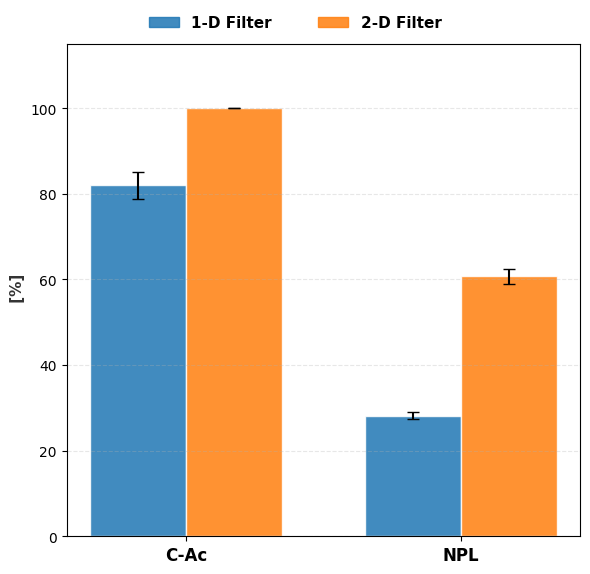

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

# --- 1. Filtered  Data ---
# Extracted C-Ac (Classification accuracy) and NPL (Normalized progression latency)
pct_metrics = ['C-Ac', 'NPL']
x_pct = np.arange(len(pct_metrics))

val_1d_pct = [82.0, 28.2]
std_1d_pct = [3.1, 0.8]

val_2d_pct = [100.0, 60.7]
std_2d_pct = [0.0, 1.7]

# --- 2. Figure Setup ---
# Setup for a single plot, adjusting the width since it's now just one panel
fig, ax = plt.subplots(figsize=(6, 5.5))
fig.patch.set_facecolor('white')

width = 0.35 

# Color Palette for 1-D vs 2-D comparison
color_1d = '#1f77b4'  # Blue
color_2d = '#ff7f0e'  # Orange
error_kw = {'elinewidth': 1.5, 'capsize': 4}

# --- 3. Plot:  ---
ax.bar(x_pct - width/2, val_1d_pct, width, yerr=std_1d_pct, 
        color=color_1d, alpha=0.85, edgecolor='white', error_kw=error_kw)
ax.bar(x_pct + width/2, val_2d_pct, width, yerr=std_2d_pct, 
        color=color_2d, alpha=0.85, edgecolor='white', error_kw=error_kw)

ax.set_ylabel(' [%]', color='#333333', fontsize=11, fontweight='bold')
ax.set_ylim(0, 115)
ax.set_xticks(x_pct)
ax.set_xticklabels(pct_metrics, fontsize=12, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.3, axis='y')
# ax.set_title('Percentage Performances', fontsize=12, fontweight='bold', pad=10)

# --- Add Unified Global Legend ---
patch_1d = mpatches.Patch(color=color_1d, alpha=0.85, label='1-D Filter')
patch_2d = mpatches.Patch(color=color_2d, alpha=0.85, label='2-D Filter')

fig.legend(handles=[patch_1d, patch_2d], 
           loc='upper center', bbox_to_anchor=(0.5, 1.05), ncol=2, frameon=False, 
           prop={'size': 11, 'weight': 'semibold'}, columnspacing=3)

# Overall Figure Title (Optional, left commented as in your original snippet)
# plt.suptitle('Overall Baseline Diagnostics: Pipeline Evaluation', 
#              fontsize=14, fontweight='bold', y=1.12)

plt.tight_layout()

# Save output to print-ready publication-grade vector PDF
plt.savefig('5-2.pdf', format='pdf', bbox_inches='tight')

# 5.3

/tmp/ipykernel_147084/1206664810.py:53: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  mpatches.Patch(color=color_1d, hatch='//', edgecolor='white', label='Adv. Limb Ischemia (1-D)'),
/tmp/ipykernel_147084/1206664810.py:54: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  mpatches.Patch(color=color_2d, hatch='//', edgecolor='white', label='Adv. Limb Ischemia (2-D)')


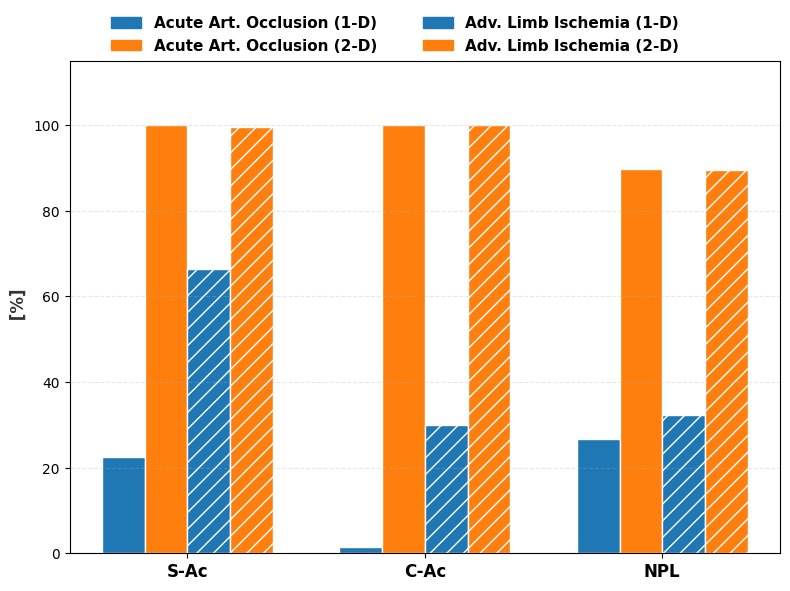

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

# --- 1. Filtered Metrics Data ---
metrics = ['S-Ac', 'C-Ac', 'NPL']
x = np.arange(len(metrics))

# --- Condition 1: Acute Art. Occlusion ---
# Values matched to ['S-Ac', 'C-Ac', 'NPL']
# NOTE: C-Ac is mathematically 0.0%, but it is padded to 1.5% here 
# so it renders as a visible sliver on the plot instead of disappearing.
val_1d_aao = [22.5, 1.5, 26.8]
val_2d_aao = [100.0, 100.0, 89.7]

# --- Condition 2: Adv. Limb Ischemia ---
# Values matched to ['S-Ac', 'C-Ac', 'NPL']
val_1d_ali = [66.5, 30.0, 32.3]
val_2d_ali = [99.5, 100.0, 89.6]

# --- 2. Figure Setup ---
fig, ax = plt.subplots(figsize=(8, 5.5))
fig.patch.set_facecolor('white')

# Bar Width & Positions (4 bars per metric group now)
width = 0.18 
offsets = [-1.5*width, -0.5*width, 0.5*width, 1.5*width]

# Exact Blue and Orange colors from the previous plot
color_1d = '#1f77b4'  # Blue
color_2d = '#ff7f0e'  # Orange

# --- 3. Plotting the Grouped Bars ---
# Acute Art. Occlusion (Solid Bars)
ax.bar(x + offsets[0], val_1d_aao, width, color=color_1d, edgecolor='white')
ax.bar(x + offsets[1], val_2d_aao, width, color=color_2d, edgecolor='white')

# Adv. Limb Ischemia (Hatched Bars to differentiate the second disease)
ax.bar(x + offsets[2], val_1d_ali, width, color=color_1d, hatch='//', edgecolor='white')
ax.bar(x + offsets[3], val_2d_ali, width, color=color_2d, hatch='//', edgecolor='white')

# --- 4. Formatting the Axis ---
ax.set_ylabel(' [%]', color='#333333', fontsize=12, fontweight='bold')
ax.set_ylim(0, 115) # Leave space at top for visual breathing room
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=12, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.3, axis='y')

# --- 5. Legend Setup ---
legend_elements = [
    mpatches.Patch(color=color_1d, label='Acute Art. Occlusion (1-D)'),
    mpatches.Patch(color=color_2d, label='Acute Art. Occlusion (2-D)'),
    mpatches.Patch(color=color_1d, hatch='//', edgecolor='white', label='Adv. Limb Ischemia (1-D)'),
    mpatches.Patch(color=color_2d, hatch='//', edgecolor='white', label='Adv. Limb Ischemia (2-D)')
]

# Set legend to 2 columns so it perfectly pairs the diseases by row
fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 1.08), 
           ncol=2, frameon=False, prop={'size': 11, 'weight': 'semibold'}, columnspacing=3)

plt.tight_layout()

# Save output to print-ready publication-grade vector PDF
plt.savefig('5-3.pdf', format='pdf', bbox_inches='tight')

# 5.4

/tmp/ipykernel_147084/648154676.py:61: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  mpatches.Patch(color=color_1d, hatch='//', edgecolor='white', label='Diabetes (1-D)'),
/tmp/ipykernel_147084/648154676.py:62: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  mpatches.Patch(color=color_2d, hatch='//', edgecolor='white', label='Diabetes (2-D)')


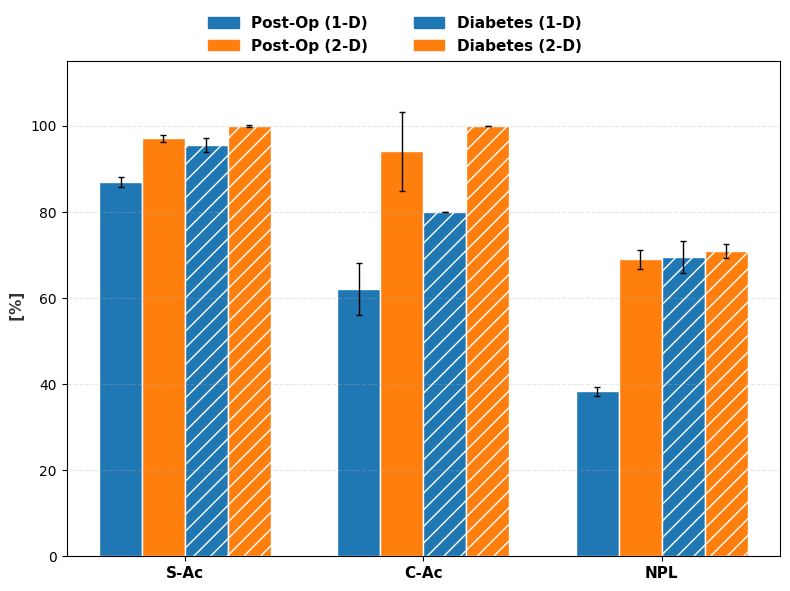

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

# --- 1. Filtered  Data ---
# Kept only the last 3 metrics: S-Ac, C-Ac, NPL
pct_metrics = ['S-Ac', 'C-Ac', 'NPL']
x_pct = np.arange(len(pct_metrics))

# Post-operative (Acute)
val_1d_pct_po = [86.9, 62.0, 38.3]
std_1d_pct_po = [1.1, 6.0, 1.0]
val_2d_pct_po = [97.1, 94.0, 69.0]
std_2d_pct_po = [0.8, 9.2, 2.2]

# Diabetes-related (Chronic)
val_1d_pct_di = [95.5, 80.0, 69.5]
std_1d_pct_di = [1.6, 0.0, 3.8]
val_2d_pct_di = [99.9, 100.0, 70.9]
std_2d_pct_di = [0.2, 0.0, 1.6]

# --- 2. Figure Setup ---
fig, ax = plt.subplots(figsize=(8, 5.5))
fig.patch.set_facecolor('white')

# Bar Width & Positions (4 bars per metric group)
width = 0.18 
offsets = [-1.5*width, -0.5*width, 0.5*width, 1.5*width]

# Exact Blue and Orange colors from the previous plots
color_1d = '#1f77b4'  # Blue
color_2d = '#ff7f0e'  # Orange

error_kw = {'elinewidth': 1.0, 'capsize': 2.5}

# --- 3. Plotting the Grouped Bars ---
# Post-operative (Solid Bars)
ax.bar(x_pct + offsets[0], val_1d_pct_po, width, bottom=0, yerr=std_1d_pct_po, 
       color=color_1d, edgecolor='white', error_kw=error_kw)
ax.bar(x_pct + offsets[1], val_2d_pct_po, width, bottom=0, yerr=std_2d_pct_po, 
       color=color_2d, edgecolor='white', error_kw=error_kw)

# Diabetes (Hatched Bars to differentiate the second cohort)
ax.bar(x_pct + offsets[2], val_1d_pct_di, width, bottom=0, yerr=std_1d_pct_di, 
       color=color_1d, hatch='//', edgecolor='white', error_kw=error_kw)
ax.bar(x_pct + offsets[3], val_2d_pct_di, width, bottom=0, yerr=std_2d_pct_di, 
       color=color_2d, hatch='//', edgecolor='white', error_kw=error_kw)

# --- 4. Formatting the Axis ---
ax.set_ylabel(' [%]', color='#333333', fontsize=11, fontweight='bold')
ax.set_ylim(0, 115)
ax.set_xticks(x_pct)
ax.set_xticklabels(pct_metrics, fontsize=11, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.3, axis='y')
# ax.set_title('Percentage Performances', fontsize=12, fontweight='bold', pad=10)

# --- 5. Legend Setup ---
legend_elements = [
    mpatches.Patch(color=color_1d, label='Post-Op (1-D)'),
    mpatches.Patch(color=color_2d, label='Post-Op (2-D)'),
    mpatches.Patch(color=color_1d, hatch='//', edgecolor='white', label='Diabetes (1-D)'),
    mpatches.Patch(color=color_2d, hatch='//', edgecolor='white', label='Diabetes (2-D)')
]

# Set legend to 2 columns to perfectly pair the cohorts by row
fig.legend(handles=legend_elements, loc='upper center', bbox_to_anchor=(0.5, 1.08), 
           ncol=2, frameon=False, prop={'size': 11, 'weight': 'semibold'}, columnspacing=3)

plt.tight_layout()

# Save output
plt.savefig('5-4.pdf', format='pdf', bbox_inches='tight')